# Loop patient 510: regular CGM gaps

The output verification screen (`2026-10-28 - Output Verification.ipynb`) flagged CGM gaps in this patient
that are one 5-minute cadence plus a whole number of hours.

**Working hypothesis, not confirmed:** a very regular overnight data dropout, maybe caused by airplane mode.

In [1]:
import os
import sys
sys.path.append(os.path.join(os.getcwd(), '..'))

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from matplotlib.ticker import ScalarFormatter

from babelbetes import data_store, drawing

NOTEBOOK = '2026-11-05 - Loop 510 CGM Gaps'
FIGURE_DIR = os.path.join('figures', NOTEBOOK)
os.makedirs(FIGURE_DIR, exist_ok=True)

%config InlineBackend.figure_format = 'retina'
# %matplotlib widget  # uncomment to zoom into the trace

## Load the patient

Only this patient's CGM is read from the store. A gap is the time between two consecutive samples.

In [2]:
STORE_PATH = os.path.join(os.getcwd(), '..', 'data', 'out')
STUDY, PATIENT = 'Loop', '510'

df_p = data_store.load(STORE_PATH, data_types=['cgm'], studies=STUDY, patients=PATIENT)['cgm'].sort_values('datetime')
df_p['gap_min'] = df_p.datetime.diff().dt.total_seconds() / 60

print(f'{len(df_p):,} samples, {df_p.datetime.min():%Y-%m-%d} to {df_p.datetime.max():%Y-%m-%d}, median gap {df_p.gap_min.median():.1f} min')

99,365 samples, 2018-05-13 to 2019-08-31, median gap 5.0 min


## Find the gaps

Same rule as in the screen: longer than an hour, and one 5-minute cadence plus a whole number of hours.
Each row is the first sample **after** a gap, so the gap starts at `gap_start` and ends at `datetime`.

In [3]:
CADENCE = 5
gaps = df_p.gap_min.round()
is_event = (gaps > 60) & ((gaps - CADENCE).mod(60) == 0)

df_events = df_p.loc[is_event, ['datetime', 'gap_min']].copy()
df_events['gap_start'] = df_events.datetime - pd.to_timedelta(df_events.gap_min, unit='min')
df_events['gap_hours'] = df_events.gap_min / 60

print(f'{len(df_events)} events')
df_events.head()

170 events


,datetime,gap_min,gap_start,gap_hours
200,2018-05-14 09:27:31,124.983333,2018-05-14 07:22:32.000000002,2.083056
13036,2018-08-13 05:33:37,304.983333,2018-08-13 00:28:38.000000002,5.083056
13257,2018-08-14 04:53:34,304.966667,2018-08-13 23:48:35.999999998,5.082778
13509,2018-08-15 06:43:29,304.950000,2018-08-15 01:38:32.000000000,5.082500
13731,2018-08-16 06:13:28,305.000000,2018-08-16 01:08:28.000000000,5.083333


## CGM trace

Shaded bands are the gaps. The lower panel zooms into the 7 days around the middle event.

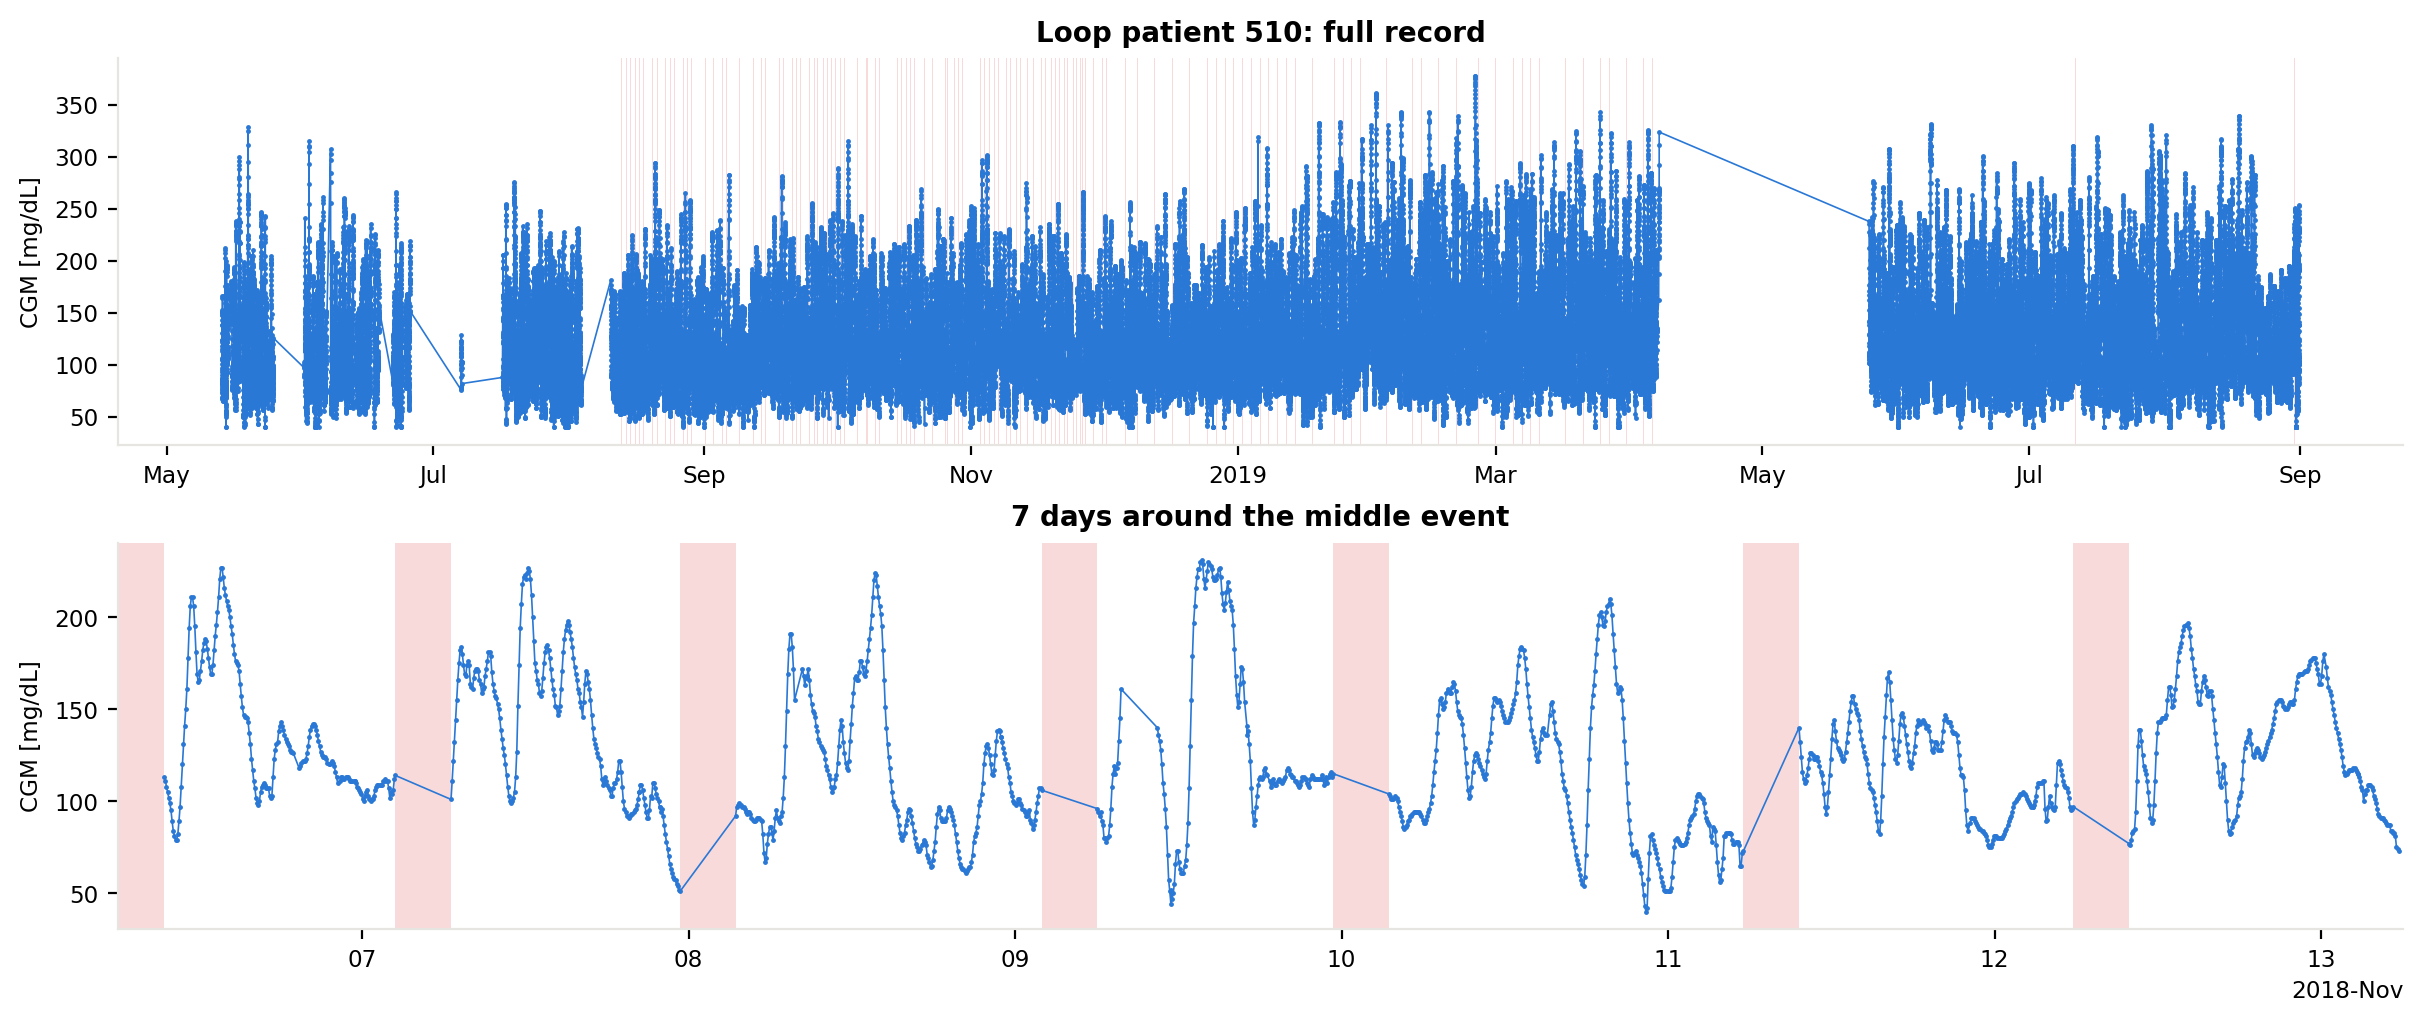

In [4]:
f, (ax_all, ax_zoom) = plt.subplots(2, 1, figsize=(12, 5), layout='constrained')

drawing.drawCGM(ax_all, df_p.datetime, df_p.cgm)
drawing.shade_gaps(ax_all, zip(df_events.gap_start, df_events.datetime))
ax_all.set_title(f'{STUDY} patient {PATIENT}: full record')

center = df_events.datetime.iloc[len(df_events) // 2]
start, end = center - np.timedelta64(3, 'D'), center + np.timedelta64(4, 'D')
df_window = df_p[df_p.datetime.between(start, end)]
drawing.drawCGM(ax_zoom, df_window.datetime, df_window.cgm)
df_window_events = df_events[df_events.datetime.between(start, end)]
drawing.shade_gaps(ax_zoom, zip(df_window_events.gap_start, df_window_events.datetime))
ax_zoom.set_xlim(start, end)
ax_zoom.set_title('7 days around the middle event')
f.savefig(os.path.join(FIGURE_DIR, 'cgm_trace.png'), dpi=300, bbox_inches='tight')


## How regular are the gaps?

- **Duration:** how long each gap lasts.
- **Time between gaps:** a jump at about 24 h would mean the gaps recur daily.
- **Time of day:** when the gaps start and end. Overnight gaps would cluster in the night hours.

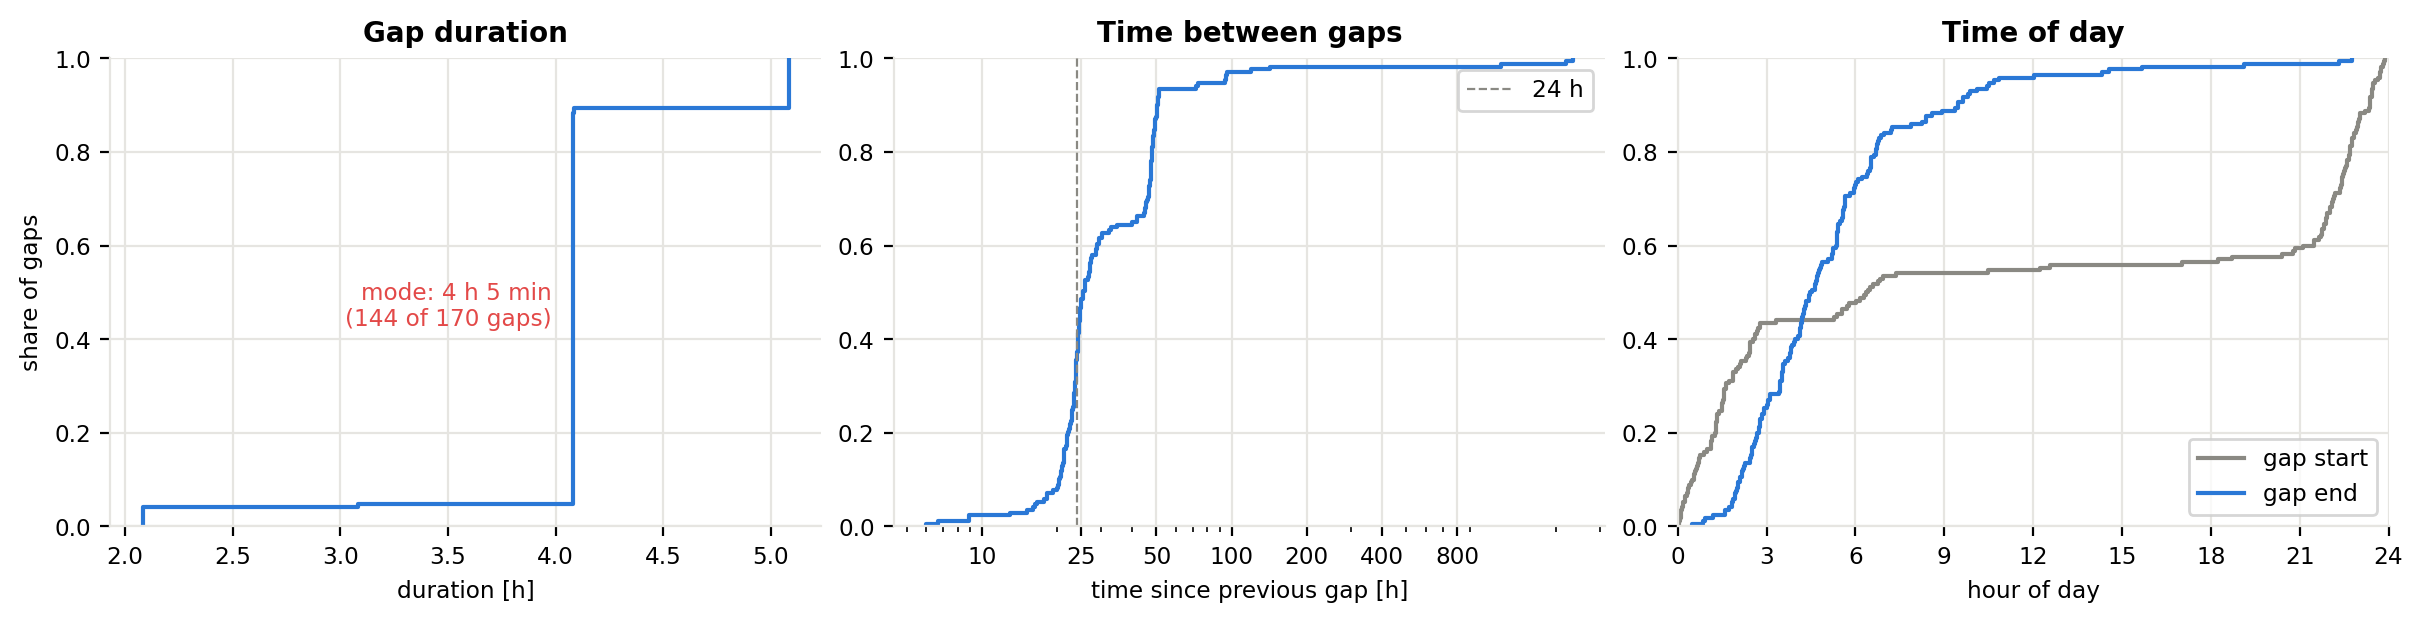

In [5]:
hours_between = df_events.datetime.diff().dt.total_seconds().dropna() / 3600
hour_of_day = lambda s: s.dt.hour + s.dt.minute / 60

f, (ax_duration, ax_between, ax_time) = plt.subplots(1, 3, figsize=(12, 3), layout='constrained')

ax_duration.ecdf(df_events.gap_hours, color=drawing.BLUE)
ax_duration.set(title='Gap duration', xlabel='duration [h]', ylabel='share of gaps')

gap_minutes = df_events.gap_min.round()
mode_min = gap_minutes.mode().iloc[0]
mode_count = (gap_minutes == mode_min).sum()
mode_y = (gap_minutes < mode_min).mean() + (mode_count / len(gap_minutes)) / 2
ax_duration.annotate(f'mode: {int(mode_min // 60)} h {int(mode_min % 60)} min\n({mode_count} of {len(gap_minutes)} gaps)',
                     (mode_min / 60, mode_y), xytext=(-8, 0), textcoords='offset points',
                     ha='right', va='center', fontsize='small', color=drawing.RED)

ax_between.ecdf(hours_between, color=drawing.BLUE)
ax_between.axvline(24, color=drawing.MUTED, linestyle='--', linewidth=0.8, label='24 h')
ax_between.set(title='Time between gaps', xlabel='time since previous gap [h]', xscale='log', xticks=[10, 25, 50, 100, 200, 400, 800])
ax_between.xaxis.set_major_formatter(ScalarFormatter())
ax_between.legend()

ax_time.ecdf(hour_of_day(df_events.gap_start), color=drawing.MUTED, label='gap start')
ax_time.ecdf(hour_of_day(df_events.datetime), color=drawing.BLUE, label='gap end')
ax_time.set(title='Time of day', xlabel='hour of day', xticks=range(0, 25, 3), xlim=(0, 24))
ax_time.legend()

for ax in (ax_duration, ax_between, ax_time):
    ax.grid(True)
f.savefig(os.path.join(FIGURE_DIR, 'gap_regularity.png'), dpi=300, bbox_inches='tight')


hours
2.0      7
3.0      1
4.0    144
5.0     18
Name: count, dtype: int64

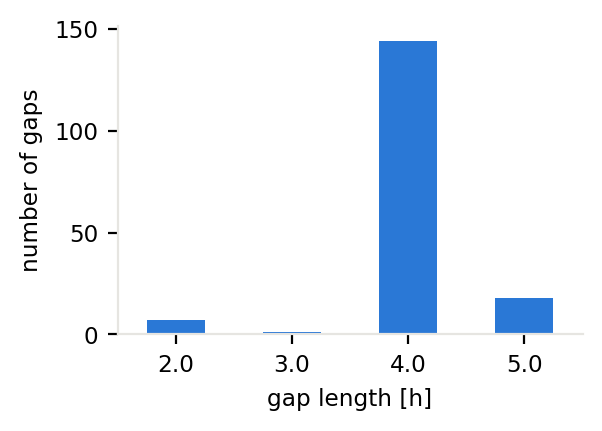

In [6]:
f, ax = drawing.default_figure(3,2)
gap_hours = ((gap_minutes - 5) / 60).value_counts().sort_index().rename_axis('hours')

gap_hours.plot.bar(ax=ax, color=drawing.BLUE)
ax.set(xlabel='gap length [h]', ylabel='number of gaps')
ax.tick_params(axis='x', rotation=0)
f.savefig(os.path.join(FIGURE_DIR, 'gap_hours.png'), dpi=300, bbox_inches='tight')
display(gap_hours)

## Cross-check with basal

CGM and basal on a shared x-axis, in the same 7-day window as above.

/var/folders/m4/5d02b2xs0l52lbxzbk0t3vym0000gp/T/ipykernel_54799/698062282.py:27: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


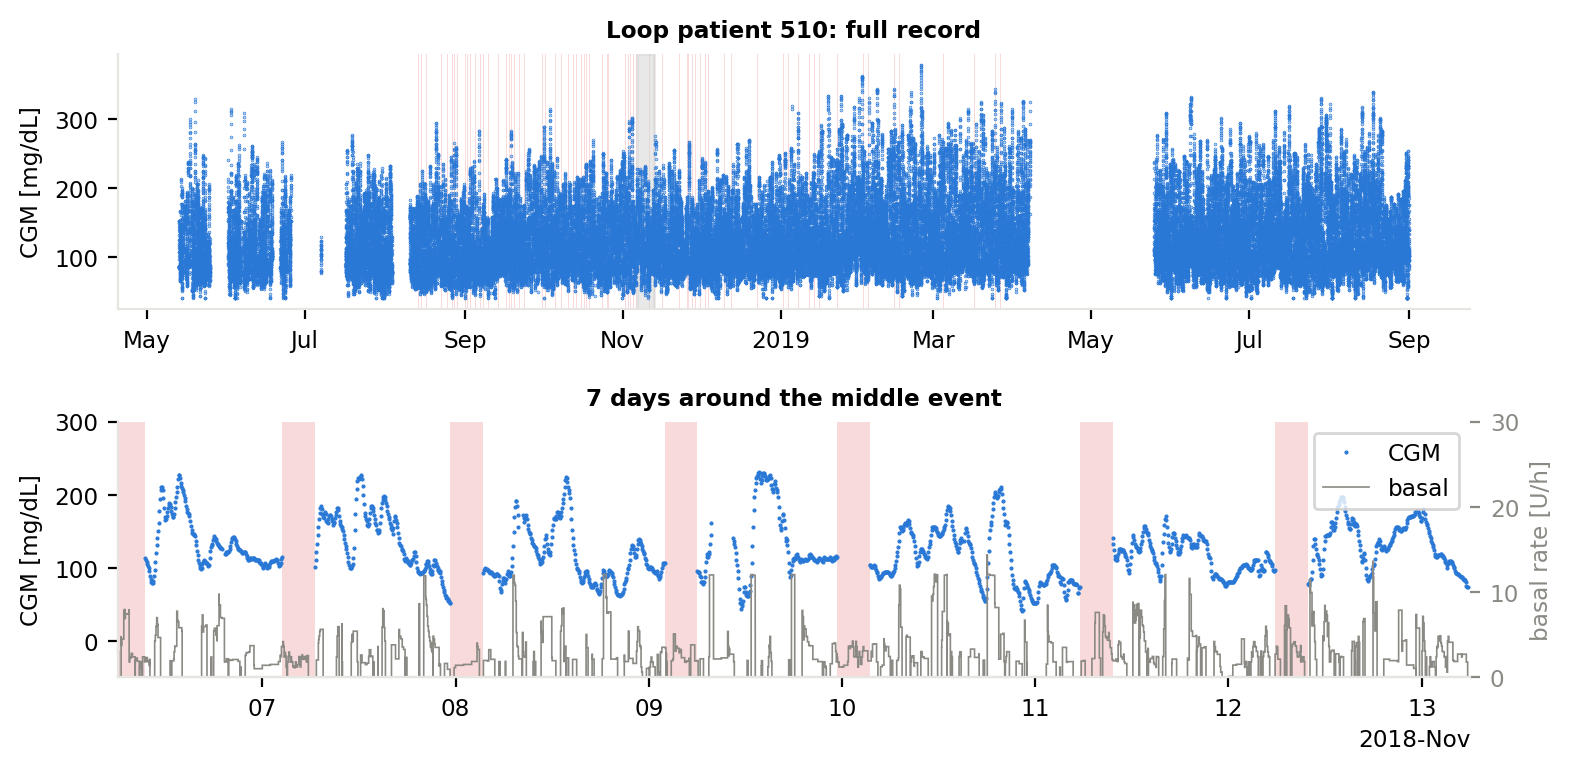

In [7]:
from importlib import reload 
reload(drawing)
df_basal = data_store.load(STORE_PATH, data_types=['basal'], studies=STUDY, patients=PATIENT)['basal'].sort_values('datetime')
df_basal_window = df_basal[df_basal.datetime.between(start, end)]
BASAL_COLOR = drawing.colors['Basal']

f, (ax_overview, ax_zoom) = plt.subplots(2, 1, figsize=(8, 4), layout='constrained')

drawing.drawCGM(ax_overview, df_p.datetime, df_p.cgm, linestyle='',markersize=.5)
drawing.shade_gaps(ax_overview, zip(df_events.gap_start, df_events.datetime))
ax_overview.axvspan(df_window.datetime.min(),df_window.datetime.max(),alpha=0.5,color='lightgray')
ax_overview.set_title(f'{STUDY} patient {PATIENT}: full record',fontsize='small')

drawing.drawCGM(ax_zoom, df_window.datetime, df_window.cgm, linestyle='',markersize=1)
df_window_events = df_events[df_events.datetime.between(start, end)]
drawing.shade_gaps(ax_zoom, zip(df_window_events.gap_start, df_window_events.datetime))
ax_zoom.set_title('7 days around the middle event',fontsize='small')
ax_zoom.set_ylim(-50,300)

ax_basal = ax_zoom.twinx()
drawing.drawBasal(ax_basal, df_basal_window.datetime, df_basal_window.basal_rate)
ax_basal.set_ylabel('basal rate [U/h]', color=BASAL_COLOR)
ax_basal.tick_params(axis='y', colors=BASAL_COLOR)
ax_basal.set_ylim(0,30)
ax_zoom.set_xlim(start, end)
ax_zoom.legend(ax_zoom.get_lines() + ax_basal.patches, ['CGM', 'basal'], loc='upper right')
plt.tight_layout()
f.savefig(os.path.join(FIGURE_DIR, 'cgm_basal_7days.png'), dpi=300, bbox_inches='tight')


## Observations
The record has 99,365 CGM samples from May 2018 to August 2019, with a median gap of 5 minutes. The gap rule finds 170 events among the 259 gaps longer than 30 minutes.

- **Fixed durations:** 144 of the 170 gaps last exactly 4 h 5 min, 18 last 5 h 5 min, 7 last 2 h 5 min and 1 lasts 3 h 5 min. This is not only an effect of the rule: of the 180 gaps between 200 and 340 minutes, 162 are a whole number of hours plus 5 minutes.
- **Overnight:** 160 of the 170 gaps start between 21:00 and 07:00.
- **Recurring:** of the 169 intervals between gaps, 85 are about one day (20-28 h) and 46 about two days (44-52 h).
- **Limited period:** 164 of the 170 gaps fall between August 2018 and March 2019.
- **Basal is not missing:** in the 7-day window, basal continues through the CGM gaps.
- **Consistent with Source** - The gaps are in the original files too.


### Interpretation

The overnight pattern is real, but the exact durations make manually switching on airplane mode less likely, because that would give varying lengths. A scheduled or automated cause would fit better. A processing artifact is not ruled out.

### Not yet checked
- If other patients in Loop or other studies show identical pattern.